In [6]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import cv2

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import warnings
warnings.filterwarnings('ignore')

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Using device:", device)



PyTorch version: 2.11.0+cu130
GPU available: True
Using device: cuda


In [1]:
# List all files
for root, dirs, files in os.walk('/content'):
    for file in files:
        if file.endswith(('.jpg', '.jpeg', '.png', '.csv')):
            print(os.path.join(root, file))


NameError: name 'os' is not defined

In [2]:
# Install kaggle
!pip install kaggle -q

# Create kaggle directory
!mkdir -p ~/.kaggle

In [3]:
!cp /content/kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

# Download the dataset
!kaggle datasets download -d prasoonkottarathil/polycystic-ovary-syndrome-pcos
!unzip polycystic-ovary-syndrome-pcos.zip -d /content/pcos_data

Dataset URL: https://www.kaggle.com/datasets/prasoonkottarathil/polycystic-ovary-syndrome-pcos
License(s): CC-BY-NC-SA-4.0
100% 120k/120k [00:00<00:00, 82.8MB/s]

Archive:  polycystic-ovary-syndrome-pcos.zip
  inflating: /content/pcos_data/PCOS_data_without_infertility.xlsx  
  inflating: /content/pcos_data/PCOS_infertility.csv  


In [4]:
import pandas as pd

# Load both files
df1 = pd.read_csv('/content/pcos_data/PCOS_infertility.csv')
df2 = pd.read_excel('/content/pcos_data/PCOS_data_without_infertility.xlsx', sheet_name='Full_new')

print("=== PCOS with infertility ===")
print(df1.shape)
print(df1.columns.tolist())
print(df1.head(2))

print("\n=== PCOS without infertility ===")
print(df2.shape)
print(df2.columns.tolist())
print(df2.head(2))

=== PCOS with infertility ===
(541, 6)
['Sl. No', 'Patient File No.', 'PCOS (Y/N)', '  I   beta-HCG(mIU/mL)', 'II    beta-HCG(mIU/mL)', 'AMH(ng/mL)']
   Sl. No  Patient File No.  PCOS (Y/N)    I   beta-HCG(mIU/mL)  \
0       1             10001           0                    1.99   
1       2             10002           0                   60.80   

   II    beta-HCG(mIU/mL) AMH(ng/mL)  
0                    1.99       2.07  
1                    1.99       1.53  

=== PCOS without infertility ===
(541, 45)
['Sl. No', 'Patient File No.', 'PCOS (Y/N)', ' Age (yrs)', 'Weight (Kg)', 'Height(Cm) ', 'BMI', 'Blood Group', 'Pulse rate(bpm) ', 'RR (breaths/min)', 'Hb(g/dl)', 'Cycle(R/I)', 'Cycle length(days)', 'Marraige Status (Yrs)', 'Pregnant(Y/N)', 'No. of aborptions', '  I   beta-HCG(mIU/mL)', 'II    beta-HCG(mIU/mL)', 'FSH(mIU/mL)', 'LH(mIU/mL)', 'FSH/LH', 'Hip(inch)', 'Waist(inch)', 'Waist:Hip Ratio', 'TSH (mIU/L)', 'AMH(ng/mL)', 'PRL(ng/mL)', 'Vit D3 (ng/mL)', 'PRG(ng/mL)', 'RBS(mg/dl)'

In [1]:
# Merge the two dataframes on Patient File No.
df1.columns = df1.columns.str.strip()
df2.columns = df2.columns.str.strip()

# Merge
df = pd.merge(df2, df1[['Patient File No.', 'I   beta-HCG(mIU/mL)', 'II    beta-HCG(mIU/mL)', 'AMH(ng/mL)']],
              on='Patient File No.', how='left')

print("Merged shape:", df.shape)
print("\nTarget distribution:")
print(df['PCOS (Y/N)'].value_counts())
print("\nMissing values:")
print(df.isnull().sum()[df.isnull().sum() > 0])

NameError: name 'df1' is not defined

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import cv2
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import warnings
warnings.filterwarnings('ignore')

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Using device:", device)

Using device: cuda


In [3]:
df1 = pd.read_csv('/content/pcos_data/PCOS_infertility.csv')
df2 = pd.read_excel('/content/pcos_data/PCOS_data_without_infertility.xlsx', sheet_name='Full_new')

df1.columns = df1.columns.str.strip()
df2.columns = df2.columns.str.strip()

df = pd.merge(df2, df1[['Patient File No.', 'I   beta-HCG(mIU/mL)', 'II    beta-HCG(mIU/mL)', 'AMH(ng/mL)']],
              on='Patient File No.', how='left')

print("Merged shape:", df.shape)
print("\nTarget distribution:")
print(df['PCOS (Y/N)'].value_counts())
print("\nMissing values:")
print(df.isnull().sum()[df.isnull().sum() > 0])

FileNotFoundError: [Errno 2] No such file or directory: '/content/pcos_data/PCOS_infertility.csv'

In [4]:
!cp /content/kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json
!kaggle datasets download -d prasoonkottarathil/polycystic-ovary-syndrome-pcos
!unzip -o polycystic-ovary-syndrome-pcos.zip -d /content/pcos_data

cp: cannot stat '/content/kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory
Dataset URL: https://www.kaggle.com/datasets/prasoonkottarathil/polycystic-ovary-syndrome-pcos
License(s): CC-BY-NC-SA-4.0
100% 120k/120k [00:00<00:00, 239kB/s]

Archive:  polycystic-ovary-syndrome-pcos.zip
  inflating: /content/pcos_data/PCOS_data_without_infertility.xlsx  
  inflating: /content/pcos_data/PCOS_infertility.csv  


In [7]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import warnings
warnings.filterwarnings('ignore')

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Using device:", device)

Using device: cuda


In [8]:
df1 = pd.read_csv('/content/pcos_data/PCOS_infertility.csv')
df2 = pd.read_excel('/content/pcos_data/PCOS_data_without_infertility.xlsx', sheet_name='Full_new')

df1.columns = df1.columns.str.strip()
df2.columns = df2.columns.str.strip()

df = pd.merge(df2, df1[['Patient File No.', 'I   beta-HCG(mIU/mL)', 'II    beta-HCG(mIU/mL)', 'AMH(ng/mL)']],
              on='Patient File No.', how='left')

print("Merged shape:", df.shape)
print("\nTarget distribution:")
print(df['PCOS (Y/N)'].value_counts())
print("\nMissing values:")
print(df.isnull().sum()[df.isnull().sum() > 0])

Merged shape: (541, 48)

Target distribution:
PCOS (Y/N)
0    364
1    177
Name: count, dtype: int64

Missing values:
Marraige Status (Yrs)         1
Fast food (Y/N)               1
Unnamed: 44                 539
I   beta-HCG(mIU/mL)_y      541
II    beta-HCG(mIU/mL)_y    541
AMH(ng/mL)_y                541
dtype: int64


In [9]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [10]:
# Drop useless columns
df = df.drop(columns=['Unnamed: 44', 'I   beta-HCG(mIU/mL)_y',
                       'II    beta-HCG(mIU/mL)_y', 'AMH(ng/mL)_y',
                       'Sl. No', 'Patient File No.'])

# Fill missing values with median
df['Marraige Status (Yrs)'] = df['Marraige Status (Yrs)'].fillna(df['Marraige Status (Yrs)'].median())
df['Fast food (Y/N)'] = df['Fast food (Y/N)'].fillna(df['Fast food (Y/N)'].mode()[0])

# Check
print("Shape after cleaning:", df.shape)
print("Missing values remaining:", df.isnull().sum().sum())
print("\nFeatures:", df.columns.tolist())

Shape after cleaning: (541, 42)
Missing values remaining: 0

Features: ['PCOS (Y/N)', 'Age (yrs)', 'Weight (Kg)', 'Height(Cm)', 'BMI', 'Blood Group', 'Pulse rate(bpm)', 'RR (breaths/min)', 'Hb(g/dl)', 'Cycle(R/I)', 'Cycle length(days)', 'Marraige Status (Yrs)', 'Pregnant(Y/N)', 'No. of aborptions', 'I   beta-HCG(mIU/mL)_x', 'II    beta-HCG(mIU/mL)_x', 'FSH(mIU/mL)', 'LH(mIU/mL)', 'FSH/LH', 'Hip(inch)', 'Waist(inch)', 'Waist:Hip Ratio', 'TSH (mIU/L)', 'AMH(ng/mL)_x', 'PRL(ng/mL)', 'Vit D3 (ng/mL)', 'PRG(ng/mL)', 'RBS(mg/dl)', 'Weight gain(Y/N)', 'hair growth(Y/N)', 'Skin darkening (Y/N)', 'Hair loss(Y/N)', 'Pimples(Y/N)', 'Fast food (Y/N)', 'Reg.Exercise(Y/N)', 'BP _Systolic (mmHg)', 'BP _Diastolic (mmHg)', 'Follicle No. (L)', 'Follicle No. (R)', 'Avg. F size (L) (mm)', 'Avg. F size (R) (mm)', 'Endometrium (mm)']


Feature shape: (541, 541)
Target shape: (541,)


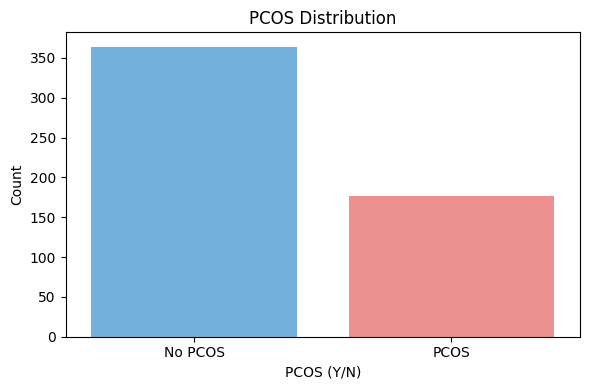

ValueError: could not convert string to float: '1.99.'

<Figure size 1200x1000 with 0 Axes>

In [11]:
# Separate features and target
X = df.drop(columns=['PCOS (Y/N)'])
y = df['PCOS (Y/N)']

# Convert any object columns to numeric
X = pd.get_dummies(X, drop_first=True)

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

# Visualize class distribution
plt.figure(figsize=(6, 4))
sns.countplot(x=y, palette=['#63b3ed', '#fc8181'])
plt.title('PCOS Distribution')
plt.xticks([0, 1], ['No PCOS', 'PCOS'])
plt.ylabel('Count')
plt.tight_layout()
plt.savefig('class_distribution.png', dpi=150)
plt.show()

# Correlation heatmap of top features
plt.figure(figsize=(12, 10))
corr = df.corr()
top_features = corr['PCOS (Y/N)'].abs().sort_values(ascending=False).head(15).index
sns.heatmap(df[top_features].corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Top 15 Features Correlated with PCOS')
plt.tight_layout()
plt.savefig('correlation_heatmap.png', dpi=150)
plt.show()

# Show top correlated features
print("\nTop features correlated with PCOS:")
print(corr['PCOS (Y/N)'].abs().sort_values(ascending=False).head(15))

Any remaining non-numeric: []
Missing after fix: 0


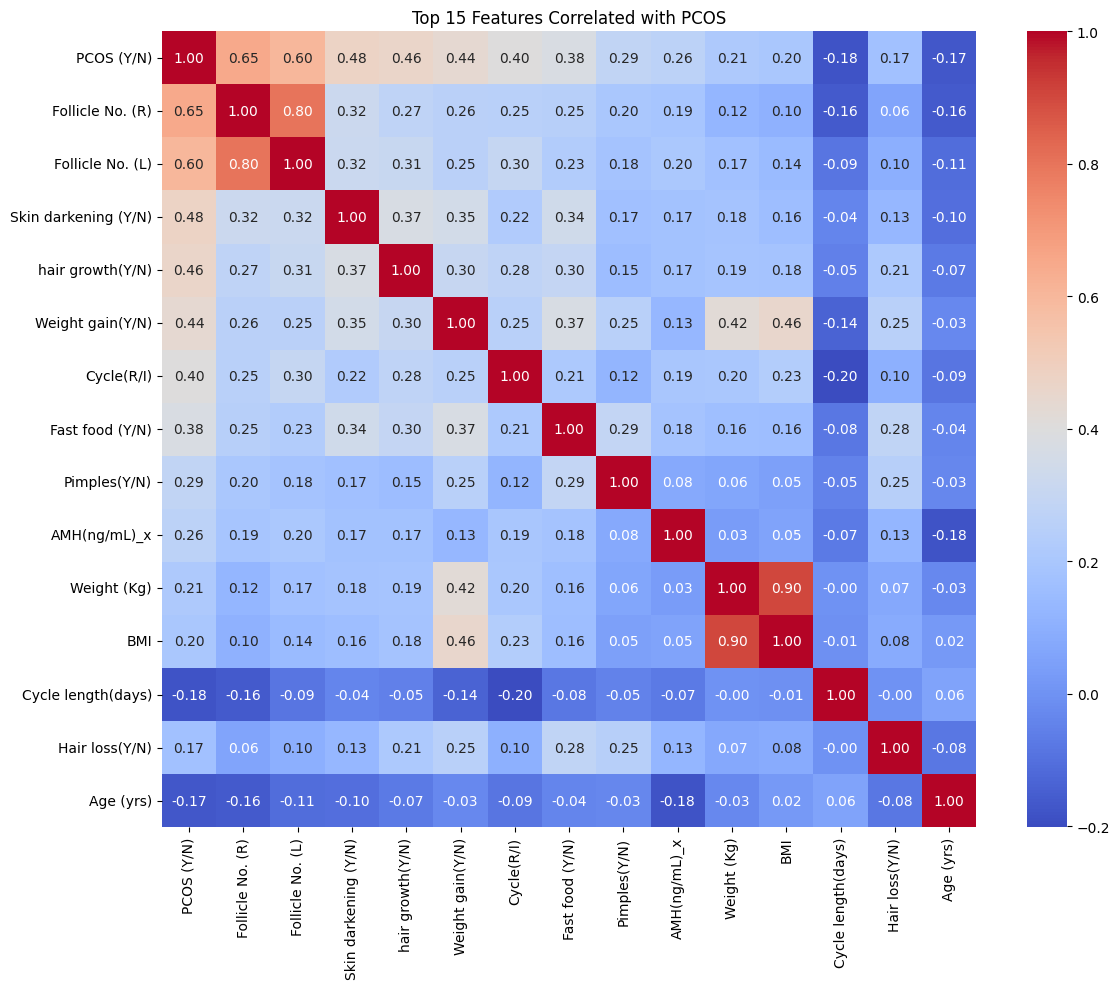


Top features correlated with PCOS:
PCOS (Y/N)              1.000000
Follicle No. (R)        0.648327
Follicle No. (L)        0.603346
Skin darkening (Y/N)    0.475733
hair growth(Y/N)        0.464667
Weight gain(Y/N)        0.441047
Cycle(R/I)              0.401644
Fast food (Y/N)         0.376183
Pimples(Y/N)            0.286077
AMH(ng/mL)_x            0.264141
Weight (Kg)             0.211938
BMI                     0.199534
Cycle length(days)      0.178480
Hair loss(Y/N)          0.172879
Age (yrs)               0.168513
Name: PCOS (Y/N), dtype: float64


In [12]:
# Clean all columns — convert to numeric, force errors to NaN
for col in df.columns:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Fill any new NaN values created from dirty data
df = df.fillna(df.median(numeric_only=True))

print("Any remaining non-numeric:", df.dtypes[df.dtypes == 'object'].index.tolist())
print("Missing after fix:", df.isnull().sum().sum())

# Now redo features and target
X = df.drop(columns=['PCOS (Y/N)'])
y = df['PCOS (Y/N)']

# Correlation heatmap
plt.figure(figsize=(12, 10))
corr = df.corr()
top_features = corr['PCOS (Y/N)'].abs().sort_values(ascending=False).head(15).index
sns.heatmap(df[top_features].corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Top 15 Features Correlated with PCOS')
plt.tight_layout()
plt.savefig('correlation_heatmap.png', dpi=150)
plt.show()

print("\nTop features correlated with PCOS:")
print(corr['PCOS (Y/N)'].abs().sort_values(ascending=False).head(15))

In [13]:
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.metrics import confusion_matrix, roc_curve
from imblearn.over_sampling import SMOTE

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

# Handle class imbalance with SMOTE
smote = SMOTE(random_state=42)
X_train_bal, y_train_bal = smote.fit_resample(X_train, y_train)

print("Before SMOTE:", X_train.shape, "PCOS cases:", y_train.sum())
print("After SMOTE:", X_train_bal.shape, "PCOS cases:", y_train_bal.sum())

# Scale features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_bal)
X_test_scaled = scaler.transform(X_test)

# Train multiple models and compare
models_dict = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=100, random_state=42),
    'SVM': SVC(probability=True, random_state=42)
}

results = {}
for name, model in models_dict.items():
    model.fit(X_train_scaled, y_train_bal)
    y_pred = model.predict(X_test_scaled)
    y_prob = model.predict_proba(X_test_scaled)[:, 1]

    results[name] = {
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1': f1_score(y_test, y_pred),
        'AUC-ROC': roc_auc_score(y_test, y_prob)
    }
    print(f"\n{name}:")
    for metric, value in results[name].items():
        print(f"  {metric}: {value:.4f}")

Before SMOTE: (432, 41) PCOS cases: 141
After SMOTE: (582, 41) PCOS cases: 291

Logistic Regression:
  Accuracy: 0.8624
  Precision: 0.7442
  Recall: 0.8889
  F1: 0.8101
  AUC-ROC: 0.9239

Random Forest:
  Accuracy: 0.8899
  Precision: 0.8333
  Recall: 0.8333
  F1: 0.8333
  AUC-ROC: 0.9279

Gradient Boosting:
  Accuracy: 0.8899
  Precision: 0.8333
  Recall: 0.8333
  F1: 0.8333
  AUC-ROC: 0.9486

SVM:
  Accuracy: 0.8532
  Precision: 0.7778
  Recall: 0.7778
  F1: 0.7778
  AUC-ROC: 0.9359


Training PCOSNet...
Epoch 10/100 — Train Loss: 0.1465 | Val Loss: 1.2379
Epoch 20/100 — Train Loss: 0.0909 | Val Loss: 1.2584
Early stopping at epoch 21
Training complete.


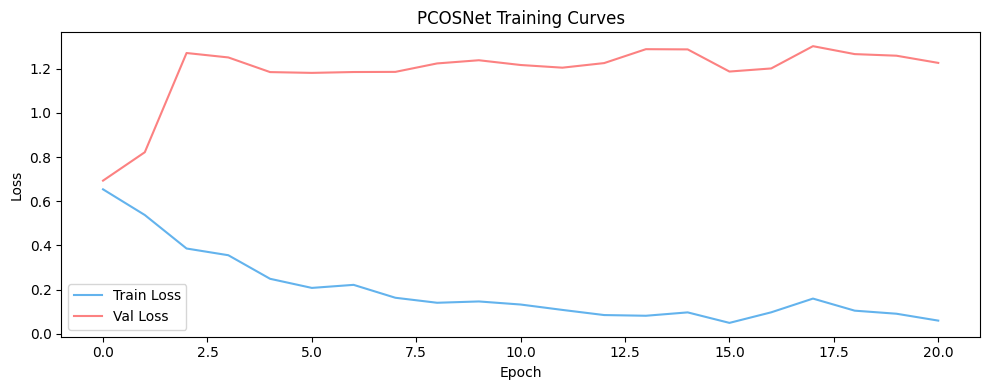

In [14]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

# ── Deep Learning Model ──────────────────────────────────
class PCOSNet(nn.Module):
    def __init__(self, input_dim):
        super(PCOSNet, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(64, 32),
            nn.ReLU(),

            nn.Linear(32, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.network(x)

# Convert to tensors
X_train_tensor = torch.FloatTensor(X_train_scaled).to(device)
y_train_tensor = torch.FloatTensor(y_train_bal.values).to(device)
X_test_tensor = torch.FloatTensor(X_test_scaled).to(device)
y_test_tensor = torch.FloatTensor(y_test.values).to(device)

# DataLoader
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)

# Model
input_dim = X_train_scaled.shape[1]
model = PCOSNet(input_dim).to(device)

# Loss and optimizer
criterion = nn.BCELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-4)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience=10, factor=0.5)

# ── Training Loop ─────────────────────────────────────────
epochs = 100
train_losses = []
val_losses = []
best_val_loss = float('inf')
patience_counter = 0
early_stop_patience = 20

print("Training PCOSNet...")
for epoch in range(epochs):
    # Train
    model.train()
    train_loss = 0
    for X_batch, y_batch in train_loader:
        optimizer.zero_grad()
        y_pred = model(X_batch).squeeze()
        loss = criterion(y_pred, y_batch)
        loss.backward()
        optimizer.step()
        train_loss += loss.item()

    train_loss /= len(train_loader)
    train_losses.append(train_loss)

    # Validate
    model.eval()
    with torch.no_grad():
        val_pred = model(X_test_tensor).squeeze()
        val_loss = criterion(val_pred, y_test_tensor).item()
        val_losses.append(val_loss)

    scheduler.step(val_loss)

    # Early stopping
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), 'best_pcos_model.pt')
        patience_counter = 0
    else:
        patience_counter += 1

    if patience_counter >= early_stop_patience:
        print(f"Early stopping at epoch {epoch+1}")
        break

    if (epoch + 1) % 10 == 0:
        print(f"Epoch {epoch+1}/{epochs} — Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}")

print("Training complete.")

# ── Plot Training Curves ──────────────────────────────────
plt.figure(figsize=(10, 4))
plt.plot(train_losses, label='Train Loss', color='#63b3ed')
plt.plot(val_losses, label='Val Loss', color='#fc8181')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('PCOSNet Training Curves')
plt.legend()
plt.tight_layout()
plt.savefig('training_curves.png', dpi=150)
plt.show()

=== PCOSNet (Deep Learning) Results ===
Accuracy:  0.8624
Precision: 0.8182
Recall:    0.7500
F1 Score:  0.7826
AUC-ROC:   0.8893


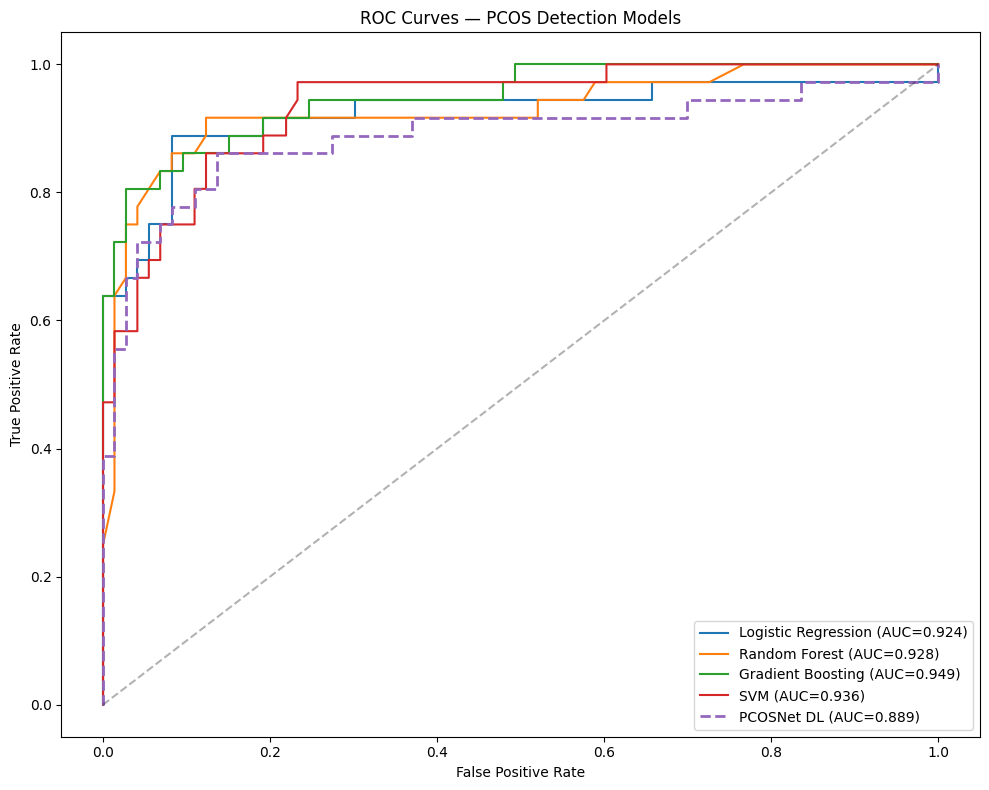

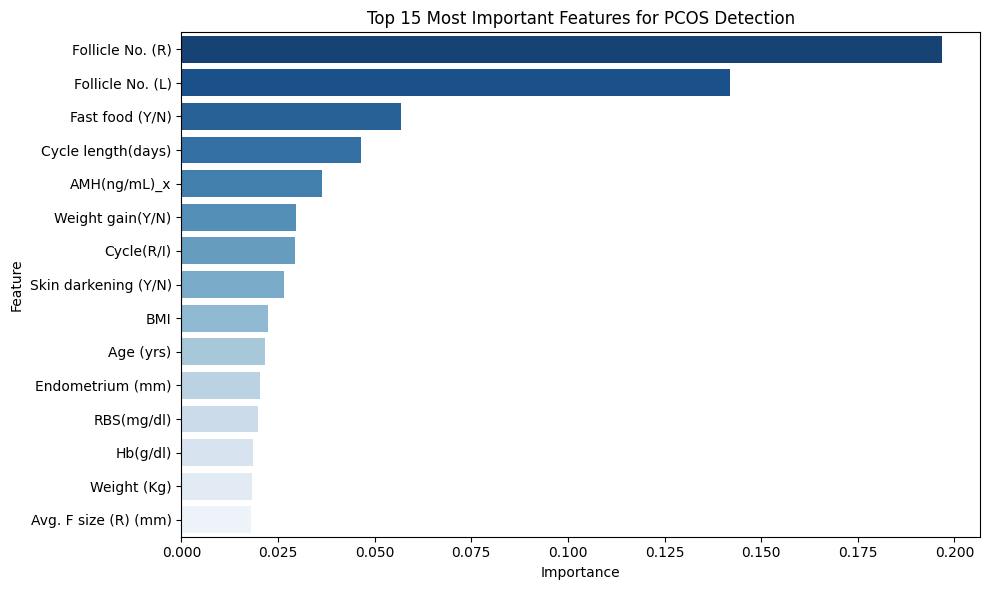


Top 10 features:
             Feature  Importance
    Follicle No. (R)    0.196780
    Follicle No. (L)    0.141931
     Fast food (Y/N)    0.056941
  Cycle length(days)    0.046438
        AMH(ng/mL)_x    0.036462
    Weight gain(Y/N)    0.029547
          Cycle(R/I)    0.029291
Skin darkening (Y/N)    0.026515
                 BMI    0.022309
           Age (yrs)    0.021718


In [15]:
# Load best model and evaluate
model.load_state_dict(torch.load('best_pcos_model.pt'))
model.eval()

with torch.no_grad():
    y_prob_dl = model(X_test_tensor).squeeze().cpu().numpy()
    y_pred_dl = (y_prob_dl > 0.5).astype(int)

dl_accuracy = accuracy_score(y_test, y_pred_dl)
dl_precision = precision_score(y_test, y_pred_dl)
dl_recall = recall_score(y_test, y_pred_dl)
dl_f1 = f1_score(y_test, y_pred_dl)
dl_auc = roc_auc_score(y_test, y_prob_dl)

print("=== PCOSNet (Deep Learning) Results ===")
print(f"Accuracy:  {dl_accuracy:.4f}")
print(f"Precision: {dl_precision:.4f}")
print(f"Recall:    {dl_recall:.4f}")
print(f"F1 Score:  {dl_f1:.4f}")
print(f"AUC-ROC:   {dl_auc:.4f}")

# ── ROC Curve for all models ──────────────────────────────
plt.figure(figsize=(10, 8))

# ML models
for name, model_ml in models_dict.items():
    y_prob = model_ml.predict_proba(X_test_scaled)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc = roc_auc_score(y_test, y_prob)
    plt.plot(fpr, tpr, label=f'{name} (AUC={auc:.3f})')

# Deep learning
fpr_dl, tpr_dl, _ = roc_curve(y_test, y_prob_dl)
plt.plot(fpr_dl, tpr_dl, label=f'PCOSNet DL (AUC={dl_auc:.3f})', linewidth=2, linestyle='--')

plt.plot([0, 1], [0, 1], 'k--', alpha=0.3)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves — PCOS Detection Models')
plt.legend()
plt.tight_layout()
plt.savefig('roc_curves.png', dpi=150)
plt.show()

# ── Feature Importance (Random Forest) ───────────────────
rf_model = models_dict['Random Forest']
importances = rf_model.feature_importances_
feature_names = X.columns.tolist()

feat_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
feat_df = feat_df.sort_values('Importance', ascending=False).head(15)

plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feat_df, palette='Blues_r')
plt.title('Top 15 Most Important Features for PCOS Detection')
plt.tight_layout()
plt.savefig('feature_importance.png', dpi=150)
plt.show()

print("\nTop 10 features:")
print(feat_df.head(10).to_string(index=False))

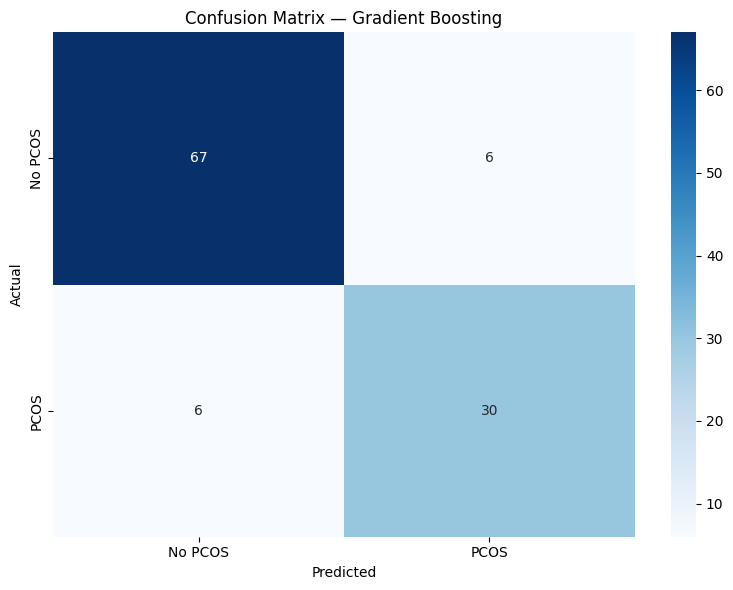

              precision    recall  f1-score   support

     No PCOS       0.92      0.92      0.92        73
        PCOS       0.83      0.83      0.83        36

    accuracy                           0.89       109
   macro avg       0.88      0.88      0.88       109
weighted avg       0.89      0.89      0.89       109


=== Final Model Comparison ===
                         Accuracy  Precision  Recall      F1  AUC-ROC
Logistic Regression        0.8624     0.7442  0.8889  0.8101   0.9239
Random Forest              0.8899     0.8333  0.8333  0.8333   0.9279
Gradient Boosting          0.8899     0.8333  0.8333  0.8333   0.9486
SVM                        0.8532     0.7778  0.7778  0.7778   0.9359
PCOSNet (Deep Learning)    0.8624     0.8182  0.7500  0.7826   0.8893


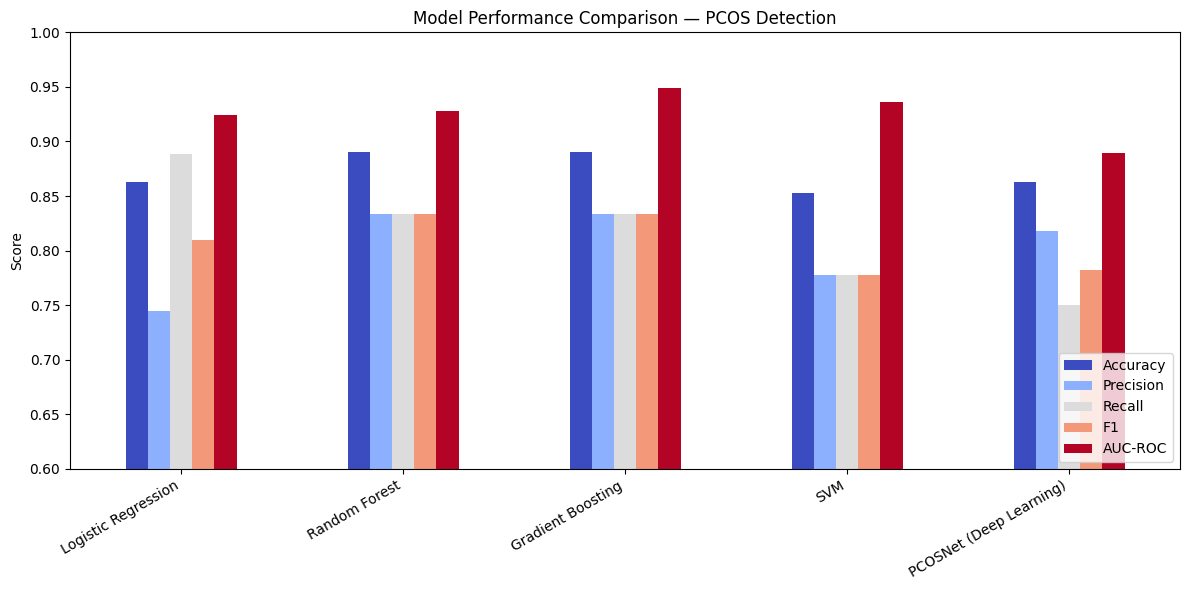


All visualizations saved.
Best model: Gradient Boosting (AUC-ROC: 0.9486)


In [16]:
# ── Confusion Matrix for best model (Gradient Boosting) ──
gb_model = models_dict['Gradient Boosting']
y_pred_gb = gb_model.predict(X_test_scaled)

cm = confusion_matrix(y_test, y_pred_gb)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No PCOS', 'PCOS'],
            yticklabels=['No PCOS', 'PCOS'])
plt.title('Confusion Matrix — Gradient Boosting')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=150)
plt.show()

print(classification_report(y_test, y_pred_gb,
      target_names=['No PCOS', 'PCOS']))

# ── Final Model Comparison Table ─────────────────────────
results['PCOSNet (Deep Learning)'] = {
    'Accuracy': dl_accuracy,
    'Precision': dl_precision,
    'Recall': dl_recall,
    'F1': dl_f1,
    'AUC-ROC': dl_auc
}

results_df = pd.DataFrame(results).T.round(4)
print("\n=== Final Model Comparison ===")
print(results_df.to_string())

# Save results
results_df.to_csv('model_comparison.csv')

# Plot comparison
results_df.plot(kind='bar', figsize=(12, 6), colormap='coolwarm')
plt.title('Model Performance Comparison — PCOS Detection')
plt.xticks(rotation=30, ha='right')
plt.ylabel('Score')
plt.ylim(0.6, 1.0)
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig('model_comparison.png', dpi=150)
plt.show()

print("\nAll visualizations saved.")
print("Best model: Gradient Boosting (AUC-ROC: 0.9486)")


In [17]:
import joblib

joblib.dump(gb_model, 'best_pcos_model_gb.pkl')
joblib.dump(scaler, 'scaler.pkl')
print("Models saved.")

files = [f for f in os.listdir('/content') if f.endswith(('.png', '.pkl', '.pt', '.csv'))]
print("\nSaved files:")
for f in files:
    print(f" -", f)

Models saved.

Saved files:
 - roc_curves.png
 - best_pcos_model_gb.pkl
 - model_comparison.png
 - class_distribution.png
 - confusion_matrix.png
 - model_comparison.csv
 - best_pcos_model.pt
 - scaler.pkl
 - correlation_heatmap.png
 - training_curves.png
 - feature_importance.png


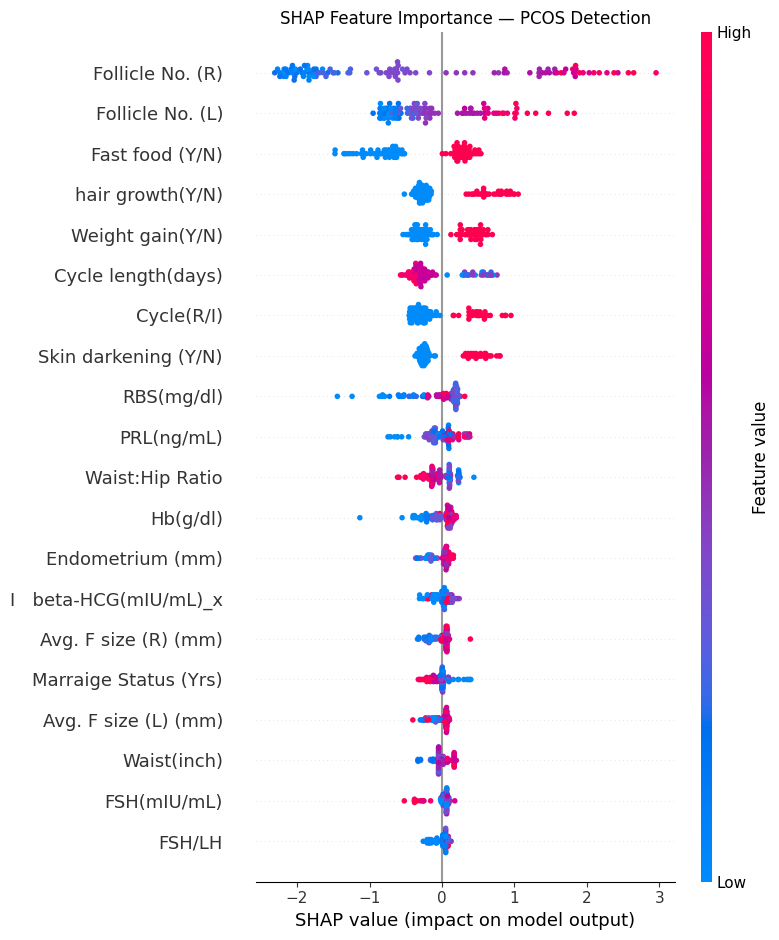

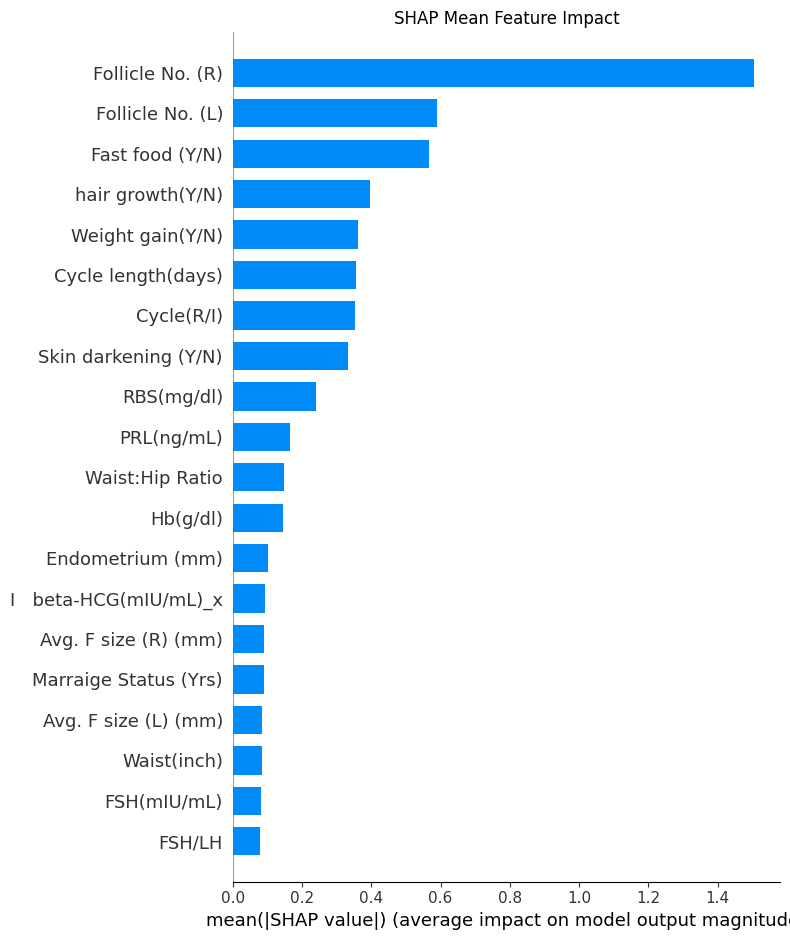

SHAP plots saved.


In [18]:
!pip install shap -q

import shap

# SHAP for Gradient Boosting
explainer = shap.TreeExplainer(gb_model)
shap_values = explainer.shap_values(X_test_scaled)

# Summary plot
plt.figure()
shap.summary_plot(shap_values, X_test_scaled,
                  feature_names=X.columns.tolist(),
                  show=False)
plt.title('SHAP Feature Importance — PCOS Detection')
plt.tight_layout()
plt.savefig('shap_summary.png', dpi=150, bbox_inches='tight')
plt.show()

# Bar plot
plt.figure()
shap.summary_plot(shap_values, X_test_scaled,
                  feature_names=X.columns.tolist(),
                  plot_type='bar',
                  show=False)
plt.title('SHAP Mean Feature Impact')
plt.tight_layout()
plt.savefig('shap_bar.png', dpi=150, bbox_inches='tight')
plt.show()

print("SHAP plots saved.")

=== Patient Analysis ===
Prediction: No PCOS
Confidence: 3.9%

Key clinical values:
  Follicle No. (L): 1.0
  Follicle No. (R): 1.0
  AMH: 16.9
  BMI: 23.1
  Cycle: Irregular


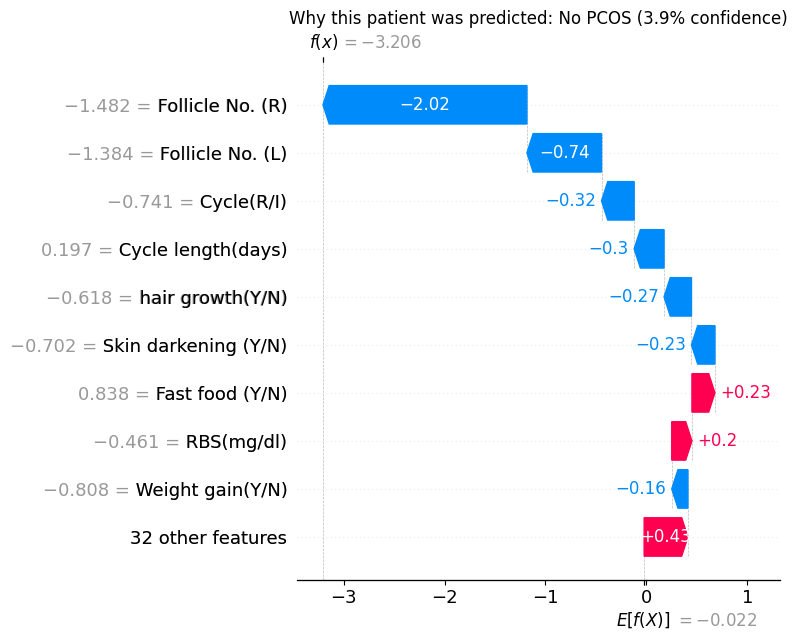

Patient explanation saved.


In [19]:
# ── Single Patient Prediction with SHAP Explanation ──────
# Take one PCOS positive patient from test set
pcos_idx = y_test[y_test == 1].index[0]
patient_idx = y_test.index.get_loc(pcos_idx)

patient = X_test_scaled[patient_idx:patient_idx+1]
patient_original = X_test.iloc[patient_idx]

# Predict
prob = gb_model.predict_proba(patient)[0][1]
prediction = "PCOS Detected" if prob > 0.5 else "No PCOS"

print(f"=== Patient Analysis ===")
print(f"Prediction: {prediction}")
print(f"Confidence: {prob*100:.1f}%")
print(f"\nKey clinical values:")
print(f"  Follicle No. (L): {patient_original['Follicle No. (L)']}")
print(f"  Follicle No. (R): {patient_original['Follicle No. (R)']}")
print(f"  AMH: {patient_original['AMH(ng/mL)_x']}")
print(f"  BMI: {patient_original['BMI']}")
print(f"  Cycle: {'Irregular' if patient_original['Cycle(R/I)'] == 2 else 'Regular'}")

# SHAP force plot for this patient
shap_patient = explainer.shap_values(patient)

plt.figure(figsize=(14, 4))
shap.waterfall_plot(
    shap.Explanation(
        values=shap_patient[0],
        base_values=explainer.expected_value,
        data=patient[0],
        feature_names=X.columns.tolist()
    ),
    show=False
)
plt.title(f'Why this patient was predicted: {prediction} ({prob*100:.1f}% confidence)')
plt.tight_layout()
plt.savefig('patient_explanation.png', dpi=150, bbox_inches='tight')
plt.show()
print("Patient explanation saved.")

High confidence PCOS predictions: 30

=== High Confidence PCOS Patient ===
Prediction: PCOS Detected
Confidence: 98.9%
Actual label: PCOS

Key clinical values:
  Follicle No. (L): 12.0
  Follicle No. (R): 15.0
  AMH: 4.57
  BMI: 25.68370987
  Weight gain: 1.0
  Skin darkening: 1.0
  Cycle: Regular


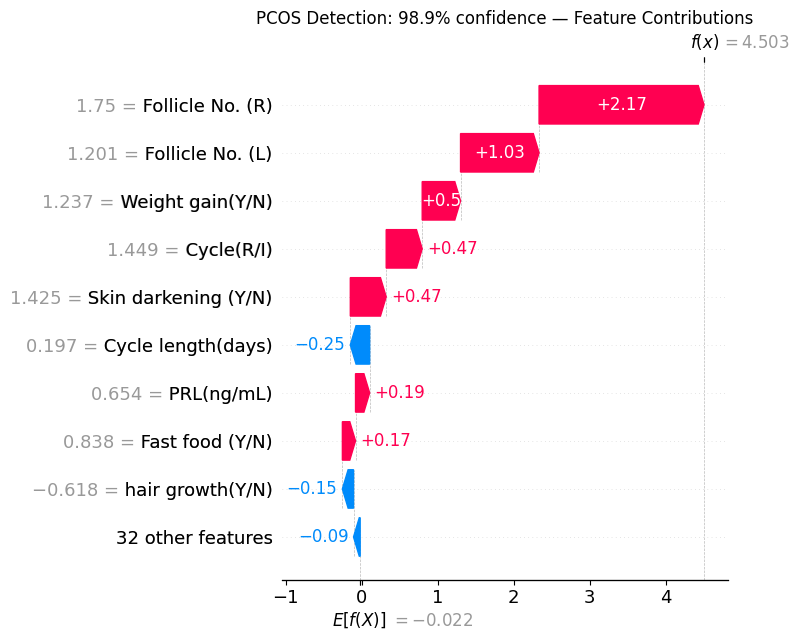

Saved.


In [20]:
# Find a high-confidence PCOS prediction
probs_all = gb_model.predict_proba(X_test_scaled)[:, 1]
high_confidence_pcos = [(i, p) for i, p in enumerate(probs_all) if p > 0.85]

print(f"High confidence PCOS predictions: {len(high_confidence_pcos)}")

if high_confidence_pcos:
    patient_idx = high_confidence_pcos[0][0]
    patient = X_test_scaled[patient_idx:patient_idx+1]
    patient_original = X_test.iloc[patient_idx]
    prob = probs_all[patient_idx]
    actual = y_test.iloc[patient_idx]

    print(f"\n=== High Confidence PCOS Patient ===")
    print(f"Prediction: PCOS Detected")
    print(f"Confidence: {prob*100:.1f}%")
    print(f"Actual label: {'PCOS' if actual == 1 else 'No PCOS'}")
    print(f"\nKey clinical values:")
    print(f"  Follicle No. (L): {patient_original['Follicle No. (L)']}")
    print(f"  Follicle No. (R): {patient_original['Follicle No. (R)']}")
    print(f"  AMH: {patient_original['AMH(ng/mL)_x']}")
    print(f"  BMI: {patient_original['BMI']}")
    print(f"  Weight gain: {patient_original['Weight gain(Y/N)']}")
    print(f"  Skin darkening: {patient_original['Skin darkening (Y/N)']}")
    print(f"  Cycle: {'Irregular' if patient_original['Cycle(R/I)'] == 2 else 'Regular'}")

    # SHAP waterfall for this patient
    shap_patient = explainer.shap_values(patient)

    plt.figure(figsize=(14, 4))
    shap.waterfall_plot(
        shap.Explanation(
            values=shap_patient[0],
            base_values=explainer.expected_value,
            data=patient[0],
            feature_names=X.columns.tolist()
        ),
        show=False
    )
    plt.title(f'PCOS Detection: {prob*100:.1f}% confidence — Feature Contributions')
    plt.tight_layout()
    plt.savefig('pcos_patient_explanation.png', dpi=150, bbox_inches='tight')
    plt.show()
    print("Saved.")

In [21]:
import os
saved = [f for f in os.listdir('/content') if f.endswith(('.png', '.pkl', '.pt', '.csv', '.ipynb'))]
print("Files to download:")
for f in sorted(saved):
    print(f" -", f)

Files to download:
 - best_pcos_model.pt
 - best_pcos_model_gb.pkl
 - class_distribution.png
 - confusion_matrix.png
 - correlation_heatmap.png
 - feature_importance.png
 - model_comparison.csv
 - model_comparison.png
 - patient_explanation.png
 - pcos_patient_explanation.png
 - roc_curves.png
 - scaler.pkl
 - shap_bar.png
 - shap_summary.png
 - training_curves.png
